In [55]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from matplotlib.patches import Rectangle, FancyArrowPatch, Arc
from networkx.drawing.nx_agraph import graphviz_layout

C:\Users\ayarmanco\AppData\Local\Temp\ipykernel_32892\1404310193.py:85: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


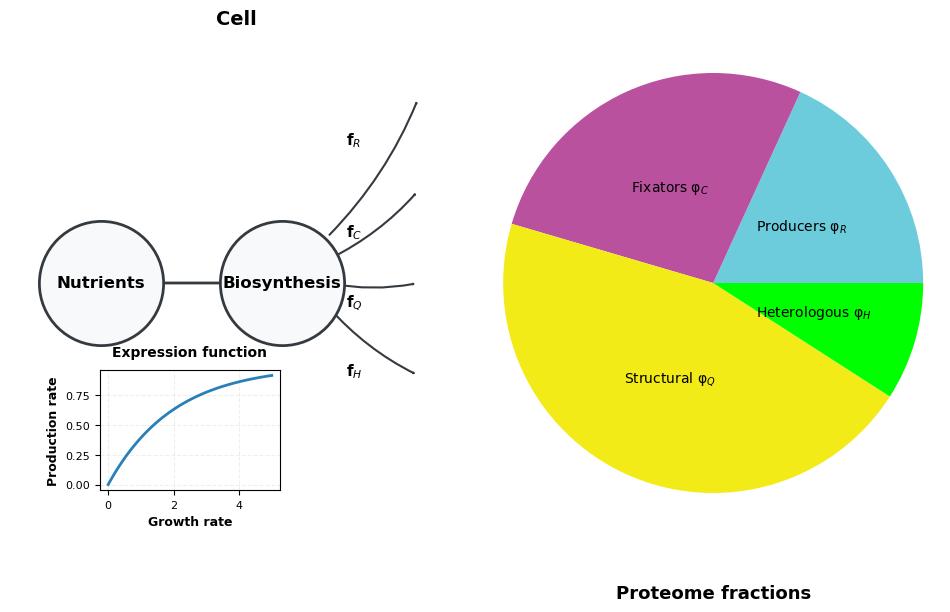

In [90]:
# Set up the figure with proper proportions
plt.style.use('default')
fig = plt.figure(figsize=(12, 6))  # Adjusted aspect ratio
plt.clf()  # Clear any existing figures

# Create subplot grid with proper spacing
gs = plt.GridSpec(1, 2, width_ratios=[1, 1], wspace=0.05)
ax_main = plt.subplot(gs[0])
ax_pie = plt.subplot(gs[1])

# Create network graph for cell components
G = nx.DiGraph()
G.add_edge('Nutrients', 'Biosynthesis')
pos = {'Nutrients': (-1, 0), 'Biosynthesis': (1, 0)}

# Draw network
nx.draw_networkx_nodes(G, pos, node_color='#f8f9fa', node_size=8000, node_shape='o',
                      edgecolors='#343a40', linewidths=2, ax=ax_main)
nx.draw_networkx_edges(G, pos, edge_color='#343a40', width=2, ax=ax_main)
nx.draw_networkx_labels(G, pos, font_size=12, font_weight='bold',ax=ax_main)

# Add arrow lines
arrow_props = dict(arrowstyle='->', linewidth=1.5, color='#343a40',
                  connectionstyle="arc3,rad=0.1")
ax_main.add_patch(FancyArrowPatch((1.5, 0.2), (2.5, 0.8), **arrow_props))
ax_main.add_patch(FancyArrowPatch((1.5, 0.1), (2.5, 0.4), **arrow_props))
ax_main.add_patch(FancyArrowPatch((1.5, 0), (2.5, 0), **arrow_props))
ax_main.add_patch(FancyArrowPatch((1.5, -0.1), (2.5, -0.4), **arrow_props))

# Add labels for fractions
ax_main.text(1.7, 0.6, 'f$_R$', fontsize=11, fontweight='bold')
ax_main.text(1.7, 0.2, 'f$_C$', fontsize=11, fontweight='bold')
ax_main.text(1.7, -0.1, 'f$_Q$', fontsize=11, fontweight='bold')
ax_main.text(1.7, -0.4, 'f$_H$', fontsize=11, fontweight='bold')

# Set main axis limits explicitly
ax_main.set_xlim(-2, 3)
ax_main.set_ylim(-1, 1)

# Create pie chart
sizes = [20, 30, 50, 10]
labels = ['Producers φ$_R$', 'Fixators φ$_C$', 'Structural φ$_Q$', 'Heterologous φ$_H$']
colors = ['#6dccdcff', '#b9519fff', '#f2eb17ff', '#00ff00ff']
#explode = (0.05, 0.05, 0.05, 0.05)

wedges, autotexts = ax_pie.pie(sizes, #labels=labels, #explode=explode, 
                                     colors=colors, autopct=None,
                                     startangle=0, textprops={'fontsize': 10},
                                     labeldistance=0.65)
plt.setp(autotexts, size=9)
#plt.setp(texts, size=10)

# Add custom labels centered in each wedge
for i, wedge in enumerate(wedges):
    # Calculate angle for each wedge
    angle = (wedge.theta1 + wedge.theta2) / 2
    x = wedge.r * 0.5 * np.cos(np.deg2rad(angle))  # Adjust to center
    y = wedge.r * 0.5 * np.sin(np.deg2rad(angle))  # Adjust to center
    ax_pie.text(x, y, labels[i], fontsize=10, ha='center', va='center')



# Add title
ax_pie.text(0, -1.5, 'Proteome fractions', fontsize=13, ha='center', fontweight='bold')

# Add small growth rate plot in a better position
ax_small = fig.add_axes([0.2, 0.15, 0.15, 0.2])  # Adjusted position and size
x = np.linspace(0, 5, 100)
y = 1 - np.exp(-x/2)
ax_small.plot(x, y, color='#2980b9', linewidth=2)
ax_small.set_xlabel('Growth rate', fontsize=9, fontweight='bold')
ax_small.set_ylabel('Production rate', fontsize=9, fontweight='bold')
ax_small.set_title('Expression function', fontsize=10, fontweight='bold', pad=10)
ax_small.grid(True, alpha=0.2, linestyle='--')
ax_small.tick_params(labelsize=8)
ax_small.spines['top'].set_visible(True)
ax_small.spines['right'].set_visible(True)

# Set titles
ax_main.set_title('Cell', fontsize=14, pad=20, fontweight='bold')
ax_main.axis('off')
ax_pie.axis('equal')

# Adjust layout
plt.tight_layout()

# Save with appropriate settings
plt.savefig('cell_proteome_diagram.png', dpi=300, bbox_inches='tight', 
            facecolor='white', edgecolor='none')
plt.show()